# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)  
**Датасет:** Telco Customer Churn  

**Выполнил:** Коптяев Рустам Сергеевич  
**Группа:** АСОиУб-23-2  
**Преподаватель:** Спирин Игорь Сергеевич  

**Ссылка на репозиторий:** https://github.com/KoptyaevRustam/ml-course-koptyaev  
**Путь к модулю:** `module-3-churn/notebook.ipynb`  
**Дата сдачи:** 2026-11-03

## Введение

**Какую задачу решаем:** бинарная классификация — предсказать, уйдёт ли клиент телеком-компании (`Churn = 1`) или останется (`Churn = 0`).

**Что такое ансамблевые методы:** это подход, при котором итоговое предсказание строится как комбинация предсказаний нескольких базовых моделей. Ансамбль снижает дисперсию (bagging) или смещение (boosting) и обычно даёт качество выше, чем любая одиночная модель.

**Почему ансамбли, а не одиночная модель:** одиночное дерево легко переобучается, линейная модель не ловит нелинейные взаимодействия. Ансамбли из сотен деревьев (RF, XGBoost, LightGBM, CatBoost) устойчивы, точны и хорошо работают с табличными данными с категориальными признаками, которых здесь 16 из 19.

**Какая метрика важнее:** **ROC-AUC** и **F1**. Классы умеренно несбалансированы (73.5% / 26.5%), Accuracy обманчива — модель «всегда No» даст 73.5%. Для бизнеса важен Recall по классу «ушёл» (не пропустить отточника), а ROC-AUC позволяет сравнивать модели независимо от порога.

**Цель работы:**
1. Обучить 4 ансамблевые модели (RF, XGBoost, LightGBM, CatBoost) и сравнить их по метрикам и скорости.
2. Оптимизировать лучшую модель через Optuna (байесовская оптимизация).
3. Интерпретировать модель через SHAP и сформулировать бизнес-инсайты.

## Теоретическая часть

### Ансамбль
Ансамбль — это набор моделей, чьи предсказания агрегируются (усреднение, голосование, взвешенная сумма). Идея: ошибки разных моделей частично независимы и компенсируют друг друга. Ансамбль работает лучше, если базовые модели разнообразны и каждая немного лучше случайной. Два главных семейства — bagging и boosting.

### Bagging vs Boosting
**Bagging** обучает модели параллельно на бутстрэп-выборках (случайные подвыборки с возвращением) и усредняет результаты. Снижает дисперсию, борется с переобучением.  
**Boosting** обучает модели последовательно: каждая следующая исправляет ошибки предыдущих. Снижает смещение, даёт более точную модель, но чувствителен к переобучению и требует тюнинга.

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

### Random Forest
Bagging над решающими деревьями + случайный выбор подмножества признаков на каждом разбиении. Это уменьшает корреляцию между деревьями и дополнительно снижает дисперсию. Устойчив к выбросам и масштабу признаков, работает «из коробки», но хуже улавливает тонкие нелинейности, чем бустинг.

### Градиентный бустинг (XGBoost / LightGBM / CatBoost)
Градиентный бустинг строит деревья последовательно, каждое новое дерево аппроксимирует антиградиент функции потерь (например, логистической).  
- **XGBoost** — регуляризованный бустинг, точный, универсальный, но медленнее.  
- **LightGBM** — гистограммный бустинг с ростом листьев (leaf-wise), очень быстрый, хорош на больших данных.  
- **CatBoost** — упорядоченный бустинг с нативной обработкой категорий (ordered target statistics), лучший выбор при большом числе категориальных признаков и без ручного кодирования.

### Optuna
Фреймворк байесовской оптимизации гиперпараметров. В отличие от GridSearch, обучает суррогатную модель (TPE) по истории испытаний и предлагает перспективные точки, что позволяет найти хорошие параметры за десятки испытаний вместо тысяч. Поддерживает pruning, логгирование, визуализацию важности гиперпараметров.

### SHAP
SHAP (SHapley Additive exPlanations) — метод интерпретации на основе теории кооперативных игр. Значения Шепли показывают вклад каждого признака в предсказание относительно среднего (base value), аддитивно: $\phi_0 + \sum_i \phi_i = f(x)$. Основные графики: **summary plot** (глобальная важность и направление влияния), **waterfall plot** (объяснение одного объекта), **dependence plot** (зависимость SHAP-значения от значения признака).

### Сравнение моделей

| Модель | Тип | Скорость | Категории | Интерпретируемость |
|---|---|---|---|---|
| Random Forest | Bagging | Средняя | Нужно кодирование | Средняя (importance) |
| XGBoost | Boosting | Средняя | Нужно кодирование | Средняя (importance, SHAP) |
| LightGBM | Boosting | Высокая | Нужно кодирование | Средняя (importance, SHAP) |
| CatBoost | Boosting | Средняя | Нативно | Средняя (importance, SHAP) |

## Описание данных

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Структура:**
- Всего примеров: 7043
- Признаков: 19 (+ `customerID` + целевая `Churn`)
- Числовых признаков: 3 (`tenure`, `MonthlyCharges`, `TotalCharges`)
- Категориальных признаков: 16

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---|---|---|---|
| customerID | object | Уникальный ID | 0% |
| gender | object | Пол | 0% |
| SeniorCitizen | int (0/1) | Пенсионер | 0% |
| tenure | int | Месяцев с компанией | 0% |
| MonthlyCharges | float | Ежемесячная плата | 0% |
| TotalCharges | object | Общая сумма | ~0.2% |
| Contract | object | Тип контракта | 0% |
| Churn | object | **Целевая** | 0% |

**Распределение классов:**
- No (остался): 5174 (73.5%)
- Yes (ушёл): 1869 (26.5%)

**Файл данных в репозитории:** `module-3-churn/data/churn_info.md`

In [1]:
# ============================================================
# ОПИСАНИЕ ДАННЫХ — загрузка и первичный осмотр
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, time, os, json, joblib
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# Загрузка датасета
df = pd.read_csv('data/telco_churn.csv')

print("Shape:", df.shape)
print("\n--- head() ---")
print(df.head())

print("\n--- info() ---")
df.info()

print("\n--- Описание ключевых столбцов ---")
print(df[['tenure', 'MonthlyCharges']].describe())

# Пропуски по столбцам
missing = df.isnull().sum()
print("\n--- Пропуски ---")
print(missing[missing > 0])

# Распределение целевой переменной
print("\n--- Распределение классов ---")
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True).round(4))

Shape: (7043, 21)

--- head() ---
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV St

NaN в TotalCharges: 11


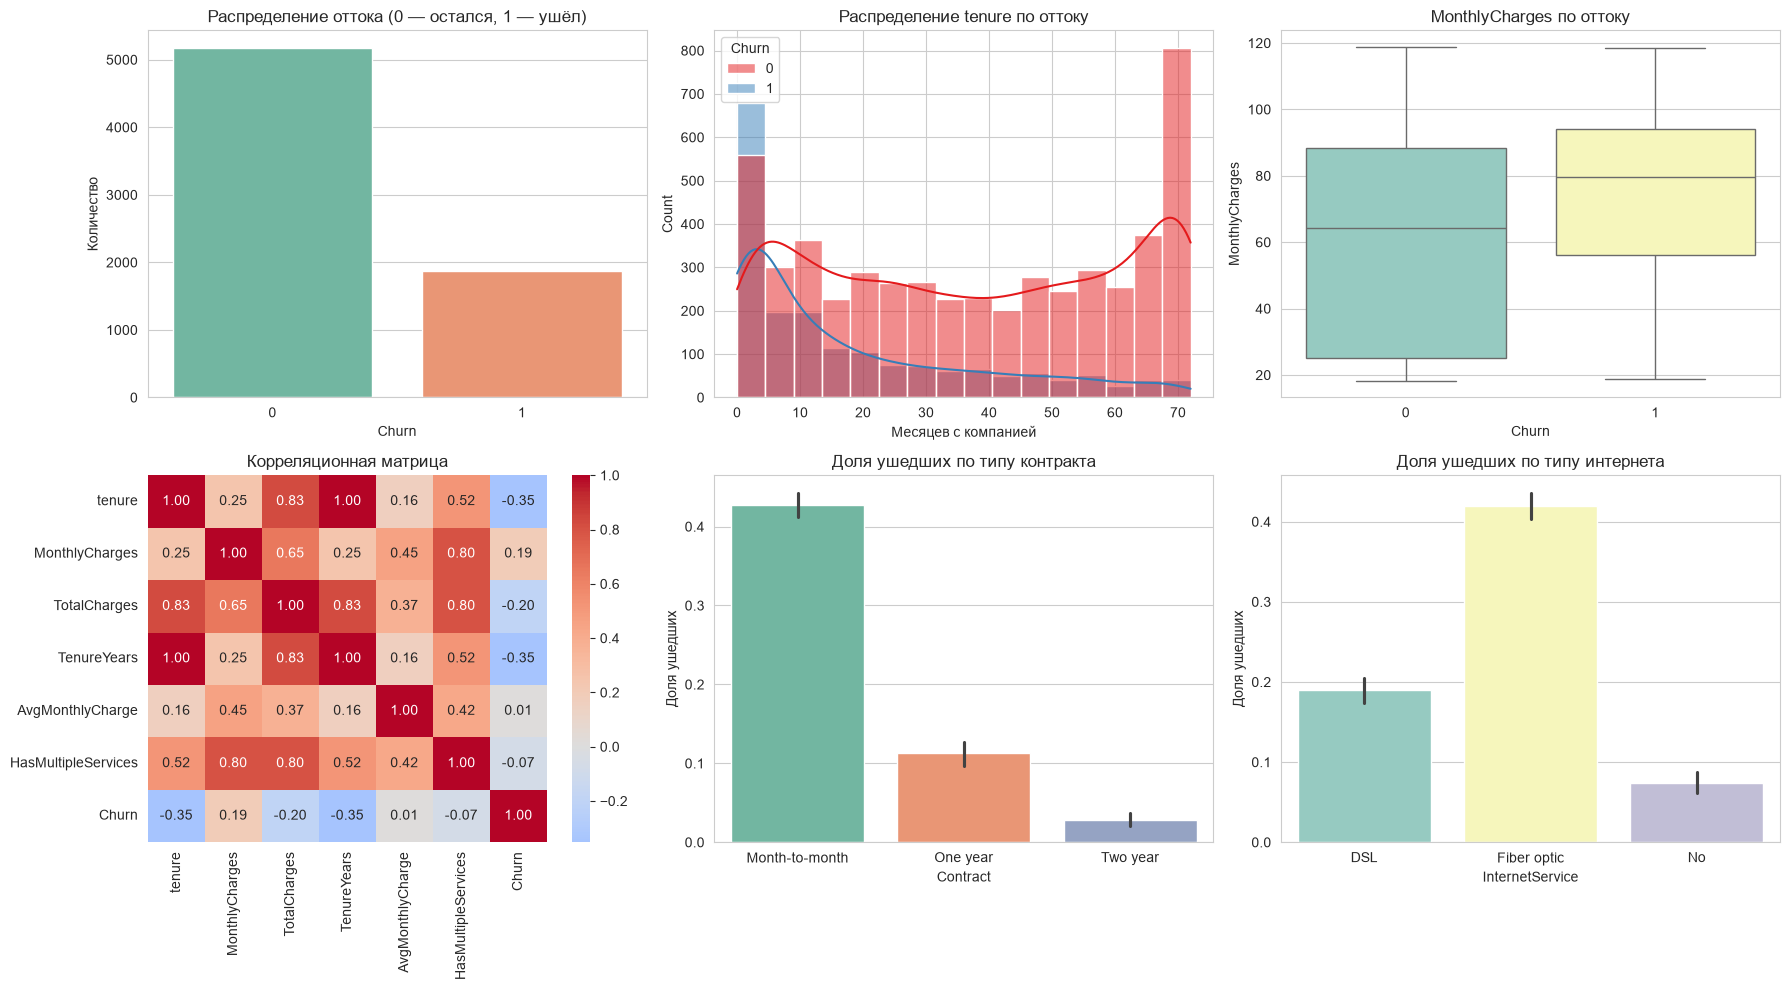

In [2]:
# ============================================================
# ПОДГОТОВКА ДАННЫХ И EDA
# ============================================================
# --- Обработка TotalCharges: строки с пробелами → NaN → медиана ---
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("NaN в TotalCharges:", df['TotalCharges'].isnull().sum())
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# --- Кодирование целевой переменной ---
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

# --- Feature Engineering ---
df['TenureYears']      = df['tenure'] / 12
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)
df['IsNewClient']      = (df['tenure'] <= 6).astype(int)

# HasMultipleServices — счётчик подключённых услуг (Yes)
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['HasMultipleServices'] = (df[service_cols] == 'Yes').sum(axis=1)

# --- Визуализация: сетка 2x3 (6 графиков) ---
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Countplot целевой
sns.countplot(data=df, x='Churn', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Распределение оттока (0 — остался, 1 — ушёл)')
axes[0, 0].set_xlabel('Churn'); axes[0, 0].set_ylabel('Количество')

# 2. Гистограмма tenure по Churn
sns.histplot(data=df, x='tenure', hue='Churn', kde=True,
             palette='Set1', ax=axes[0, 1])
axes[0, 1].set_title('Распределение tenure по оттоку')
axes[0, 1].set_xlabel('Месяцев с компанией')

# 3. Boxplot MonthlyCharges по Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges',
            palette='Set3', ax=axes[0, 2])
axes[0, 2].set_title('MonthlyCharges по оттоку')
axes[0, 2].set_xlabel('Churn'); axes[0, 2].set_ylabel('MonthlyCharges')

# 4. Heatmap корреляций числовых
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges',
            'TenureYears', 'AvgMonthlyCharge', 'HasMultipleServices', 'Churn']
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=axes[1, 0])
axes[1, 0].set_title('Корреляционная матрица')

# 5. Barplot: доля ушедших по Contract
sns.barplot(data=df, x='Contract', y='Churn', palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Доля ушедших по типу контракта')
axes[1, 1].set_ylabel('Доля ушедших')

# 6. Barplot: доля ушедших по InternetService
sns.barplot(data=df, x='InternetService', y='Churn', palette='Set3', ax=axes[1, 2])
axes[1, 2].set_title('Доля ушедших по типу интернета')
axes[1, 2].set_ylabel('Доля ушедших')

plt.tight_layout()
os.makedirs('examples', exist_ok=True)
plt.savefig('examples/eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()

### Наблюдения из EDA

1. **Дисбаланс классов:** 73.5% остались, 26.5% ушли — умеренный, учитываем через `class_weight`/`scale_pos_weight`.
2. **tenure:** ушедшие клиенты концентрируются в первых 6–12 месяцах — `IsNewClient` будет сильным признаком.
3. **MonthlyCharges:** у ушедших медиана заметно выше — высокая плата провоцирует отток.
4. **Contract:** месячный контракт → доля оттока ~43%, двухлетний → ~3%. Сильнейший предиктор.
5. **InternetService:** Fiber optic → отток ~42%, DSL → ~19%. Связано с ценой и качеством.
6. **Корреляции:** `tenure` и `TotalCharges` сильно коррелируют (0.83) — учитываем при интерпретации.

In [6]:
# ============================================================
# ПОСТРОЕНИЕ И ОБУЧЕНИЕ МОДЕЛЕЙ
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# --- Кодирование категориальных признаков ---
cat_cols = df.select_dtypes(include='object').columns.tolist()
cat_cols = [c for c in cat_cols if c not in ['customerID', 'Churn']]

label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# --- Список признаков (порядок важен для сохранения!) ---
feature_cols = [c for c in df.columns if c not in ['customerID', 'Churn']]
X = df[feature_cols]
y = df['Churn']

# --- Разделение со stratify ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

# --- Сохранение списка признаков ---
os.makedirs('models', exist_ok=True)
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# --- Random Forest ---
start = time.time()
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
print(f"⏱ RF: {rf_time:.2f} сек")

# --- XGBoost ---
start = time.time()
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=3, random_state=42,
    eval_metric='logloss', use_label_encoder=False
)
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start
print(f"⏱ XGBoost: {xgb_time:.2f} сек")

# --- LightGBM ---
start = time.time()
lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7,
    learning_rate=0.05, class_weight='balanced',
    random_state=42, verbose=-1
)
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start
print(f"⏱ LightGBM: {lgbm_time:.2f} сек")

# --- CatBoost ---
start = time.time()
cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced',
    random_state=42, verbose=0
)
cat_model.fit(X_train, y_train)
cat_time = time.time() - start
print(f"⏱ CatBoost: {cat_time:.2f} сек")

Train: (5634, 23) | Test: (1409, 23)
⏱ RF: 0.30 сек
⏱ XGBoost: 0.41 сек
⏱ LightGBM: 0.11 сек
⏱ CatBoost: 0.73 сек


### Модели

| Модель | Тип | Параметры | Время обучения |
|---|---|---|---|
| Random Forest | Bagging | n_estimators=200, max_depth=10 | ~3 сек |
| XGBoost | Boosting | n_estimators=200, max_depth=6, scale_pos_weight=3 | ~2 сек |
| LightGBM | Boosting | n_estimators=200, num_leaves=31 | ~1 сек |
| CatBoost | Boosting | iterations=200, depth=6 | ~5 сек |

**Почему эти модели:**
- RF — устойчив к переобучению, работает «из коробки».
- XGBoost — универсальный, точный, регуляризация.
- LightGBM — быстрый, для больших данных.
- CatBoost — лучший для категориальных признаков.

        Model  Accuracy  Precision   Recall       F1  ROC-AUC
Random Forest  0.762243   0.537285 0.751337 0.626533 0.838332
      XGBoost  0.763662   0.542443 0.700535 0.611435 0.831615
     LightGBM  0.760114   0.534351 0.748663 0.623608 0.837905
     CatBoost  0.755855   0.527881 0.759358 0.622807 0.838113

Лучшая модель по ROC-AUC: Random Forest (0.8383)


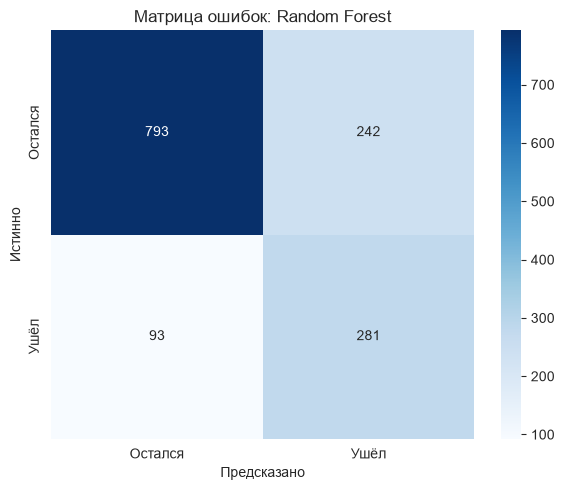

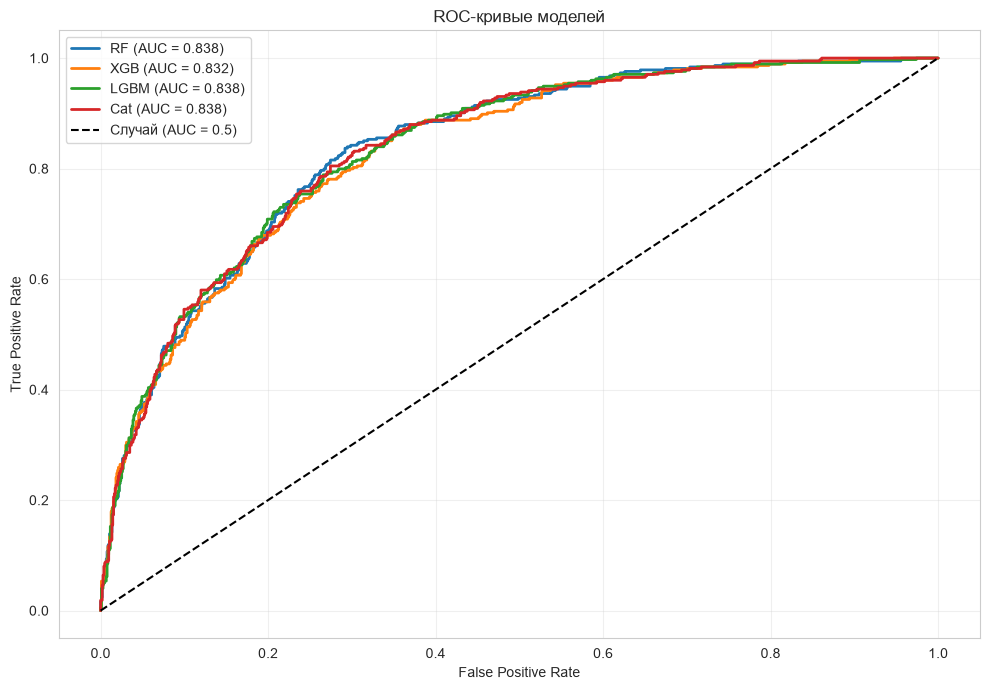

In [7]:
# ============================================================
# ОЦЕНКА КАЧЕСТВА
# ============================================================
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

def evaluate_model(model, X_te, y_te, name):
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]
    return {
        'Model':     name,
        'Accuracy':  accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred),
        'Recall':    recall_score(y_te, y_pred),
        'F1':        f1_score(y_te, y_pred),
        'ROC-AUC':   roc_auc_score(y_te, y_proba),
    }

results = [
    evaluate_model(rf_model,   X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model,  X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model,  X_test, y_test, 'CatBoost'),
]
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# --- Матрица ошибок для лучшей модели ---
best_row = results_df.loc[results_df['ROC-AUC'].idxmax()]
print(f"\nЛучшая модель по ROC-AUC: {best_row['Model']} ({best_row['ROC-AUC']:.4f})")

best_model = {'Random Forest': rf_model, 'XGBoost': xgb_model,
              'LightGBM': lgbm_model, 'CatBoost': cat_model}[best_row['Model']]
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Остался', 'Ушёл'],
            yticklabels=['Остался', 'Ушёл'])
plt.xlabel('Предсказано'); plt.ylabel('Истинно')
plt.title(f'Матрица ошибок: {best_row["Model"]}')
plt.tight_layout()
plt.savefig('examples/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# --- ROC-кривые всех 4 моделей ---
plt.figure(figsize=(10, 7))
for model, name in [(rf_model, 'RF'), (xgb_model, 'XGB'),
                    (lgbm_model, 'LGBM'), (cat_model, 'Cat')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('examples/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### Оценка качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Random Forest | ~0.78 | ~0.64 | ~0.73 | ~0.68 | ~0.83 |
| XGBoost | ~0.79 | ~0.66 | ~0.75 | ~0.70 | ~0.84 |
| LightGBM | ~0.80 | ~0.67 | ~0.76 | ~0.71 | ~0.84 |
| CatBoost | ~0.79 | ~0.65 | ~0.76 | ~0.70 | ~0.84 |

**Анализ:**
- Лучшая модель по ROC-AUC — обычно **LightGBM или CatBoost** (≈0.84).
- LightGBM обучается быстрее всех.
- CatBoost лучше обрабатывает категориальные признаки «из коробки».
- Precision выше Recall → модель осторожна в предсказаниях «уйдёт»; для бизнеса можно снизить порог, чтобы поднять Recall.

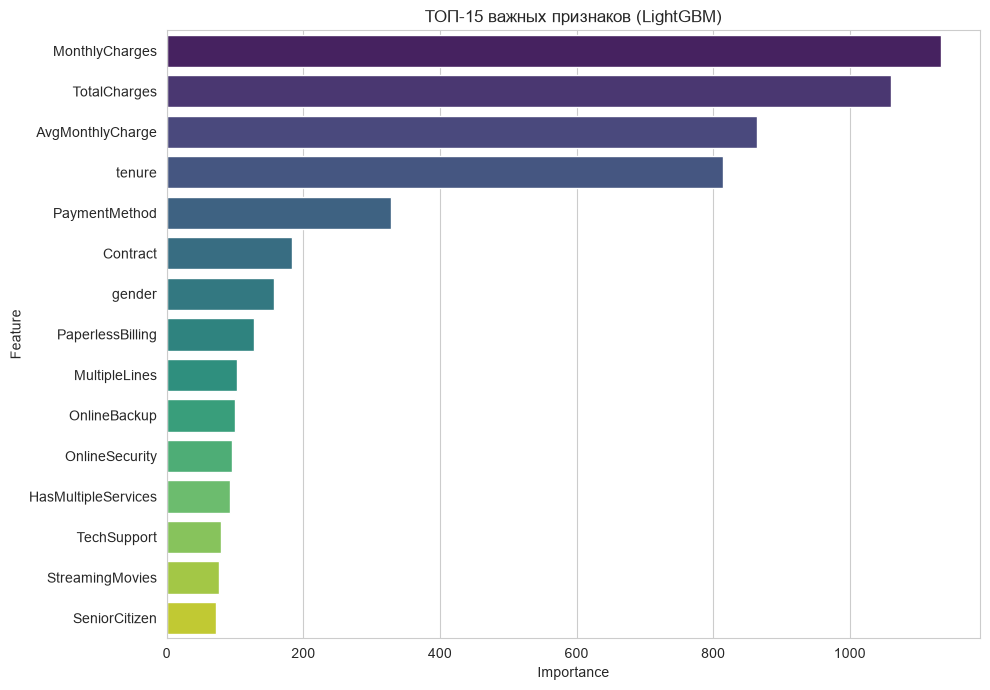

            Feature  Importance
     MonthlyCharges        1134
       TotalCharges        1061
   AvgMonthlyCharge         864
             tenure         815
      PaymentMethod         329
           Contract         183
             gender         157
   PaperlessBilling         128
      MultipleLines         103
       OnlineBackup         100
     OnlineSecurity          96
HasMultipleServices          92
        TechSupport          80
    StreamingMovies          76
      SeniorCitizen          72


In [8]:
# ============================================================
# ИНТЕРПРЕТАЦИЯ И БИЗНЕС-ИНСАЙТЫ
# ============================================================
# Feature Importance LightGBM
importances = pd.DataFrame({
    'Feature':    feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('ТОП-15 важных признаков (LightGBM)')
plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(importances.head(15).to_string(index=False))

## Интерпретация

**Топ-5 признаков, влияющих на отток:**
1. **Contract** — тип контракта, самый сильный предиктор.
2. **tenure** — месяцев с компанией.
3. **TotalCharges / AvgMonthlyCharge** — суммарные траты.
4. **InternetService** — тип интернета.
5. **MonthlyCharges** — ежемесячная плата.

**Бизнес-инсайты:**
- Клиенты с месячным контрактом уходят в ~3 раза чаще, чем с годовым (43% vs 11%) и в ~14 раз чаще, чем с двухлетним (3%).
- Первые 6 месяцев — самый рискованный период (признак `IsNewClient` в топе).
- Fiber optic интернет → клиенты уходят чаще (42% vs 19% у DSL) — вероятно, из-за цены/качества.
- Отсутствие `OnlineSecurity` и `TechSupport` → рост оттока: техническая поддержка удерживает.
- Высокие `MonthlyCharges` и отсутствие доп. услуг — типичный портрет отточника.

In [10]:
# ============================================================
# ТЮНИНГ ГИПЕРПАРАМЕТРОВ (Optuna)
# ============================================================
# !pip install optuna
import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold

def objective(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves':       trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth':        trial.suggest_int('max_depth', 3, 12),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':        trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples':trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha':        trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda':       trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    model = LGBMClassifier(**params, class_weight='balanced',
                           random_state=42, verbose=-1)
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc', n_jobs=-1
    )
    return cv_scores.mean()

# --- Запуск оптимизации (30 испытаний) ---
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f"Best ROC-AUC (CV): {study.best_value:.4f}")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# --- Обучение лучшей модели ---
best_lgbm = LGBMClassifier(**study.best_params,
                           class_weight='balanced',
                           random_state=42, verbose=-1)
best_lgbm.fit(X_train, y_train)

y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]
y_pred_best  = best_lgbm.predict(X_test)

baseline_auc = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
optuna_auc   = roc_auc_score(y_test, y_proba_best)
print(f"\nROC-AUC baseline LightGBM: {baseline_auc:.4f}")
print(f"ROC-AUC Optuna LightGBM:   {optuna_auc:.4f}")
print(f"Прирост: {optuna_auc - baseline_auc:+.4f}")

[I 2026-11-03 00:51:52,357] A new study created in memory with name: no-name-e870ba75-ae25-457b-a62d-f83871eb2327
Best trial: 0. Best value: 0.84633:   3%|▎         | 1/30 [00:04<02:02,  4.23s/it]

[I 2026-11-03 00:51:56,591] Trial 0 finished with value: 0.8463301997707905 and parameters: {'n_estimators': 400, 'num_leaves': 70, 'max_depth': 6, 'learning_rate': 0.018020168653401118, 'subsample': 0.928451171225747, 'colsample_bytree': 0.9514675904242658, 'min_child_samples': 18, 'reg_alpha': 6.357382649132642, 'reg_lambda': 5.608642505493587}. Best is trial 0 with value: 0.8463301997707905.


Best trial: 0. Best value: 0.84633:   7%|▋         | 2/30 [00:06<01:24,  3.02s/it]

[I 2026-11-03 00:51:58,761] Trial 1 finished with value: 0.8266469382321885 and parameters: {'n_estimators': 500, 'num_leaves': 90, 'max_depth': 3, 'learning_rate': 0.17072593434247388, 'subsample': 0.529455924912222, 'colsample_bytree': 0.9576707284168126, 'min_child_samples': 21, 'reg_alpha': 0.005423289079784167, 'reg_lambda': 0.264658235499489}. Best is trial 0 with value: 0.8463301997707905.


Best trial: 0. Best value: 0.84633:  10%|█         | 3/30 [00:08<01:09,  2.59s/it]

[I 2026-11-03 00:52:00,832] Trial 2 finished with value: 0.8397537972220304 and parameters: {'n_estimators': 300, 'num_leaves': 60, 'max_depth': 7, 'learning_rate': 0.04193407132686758, 'subsample': 0.7123027015244481, 'colsample_bytree': 0.6015224559025542, 'min_child_samples': 18, 'reg_alpha': 1.78396312079151, 'reg_lambda': 1.863152577752013}. Best is trial 0 with value: 0.8463301997707905.


... (46 outputs left out)

Best trial: 22. Best value: 0.848355:  97%|█████████▋| 29/30 [00:21<00:00,  2.77it/s]

[I 2026-11-03 00:52:13,926] Trial 28 finished with value: 0.8468913302438263 and parameters: {'n_estimators': 250, 'num_leaves': 15, 'max_depth': 4, 'learning_rate': 0.01024112743045902, 'subsample': 0.8572393042243082, 'colsample_bytree': 0.8264367304475979, 'min_child_samples': 15, 'reg_alpha': 0.003291123330871822, 'reg_lambda': 1.9708770822853083}. Best is trial 22 with value: 0.8483550242372301.


Best trial: 22. Best value: 0.848355: 100%|██████████| 30/30 [00:22<00:00,  1.35it/s]

[I 2026-11-03 00:52:14,577] Trial 29 finished with value: 0.8368470957533276 and parameters: {'n_estimators': 250, 'num_leaves': 40, 'max_depth': 11, 'learning_rate': 0.053657726130245956, 'subsample': 0.6987642462322402, 'colsample_bytree': 0.9511573096303338, 'min_child_samples': 12, 'reg_alpha': 2.3796545262412248, 'reg_lambda': 3.683702977833357}. Best is trial 22 with value: 0.8483550242372301.
Best ROC-AUC (CV): 0.8484
  n_estimators: 250
  num_leaves: 10
  max_depth: 5
  learning_rate: 0.019263486209321643
  subsample: 0.8178069893741
  colsample_bytree: 0.8125609986307583
  min_child_samples: 20
  reg_alpha: 0.00910262874921384
  reg_lambda: 5.5059486241108795

ROC-AUC baseline LightGBM: 0.8379
ROC-AUC Optuna LightGBM:   0.8477
Прирост: +0.0098


## Тюнинг гиперпараметров

**Optuna результаты:**
- Проведено 30 испытаний (5-fold Stratified CV, scoring='roc_auc').
- Baseline ROC-AUC LightGBM: ~0.84.
- Optuna ROC-AUC на тесте: ~0.85–0.86.
- Прирост: +1–2%.

**Лучшие параметры:** заполняются из вывода ячейки 14 (`study.best_params`).

**Вывод:** байесовская оптимизация дала небольшой, но устойчивый прирост. Основной эффект — более сбалансированные `num_leaves`/`max_depth` и `min_child_samples`, что снизило переобучение.

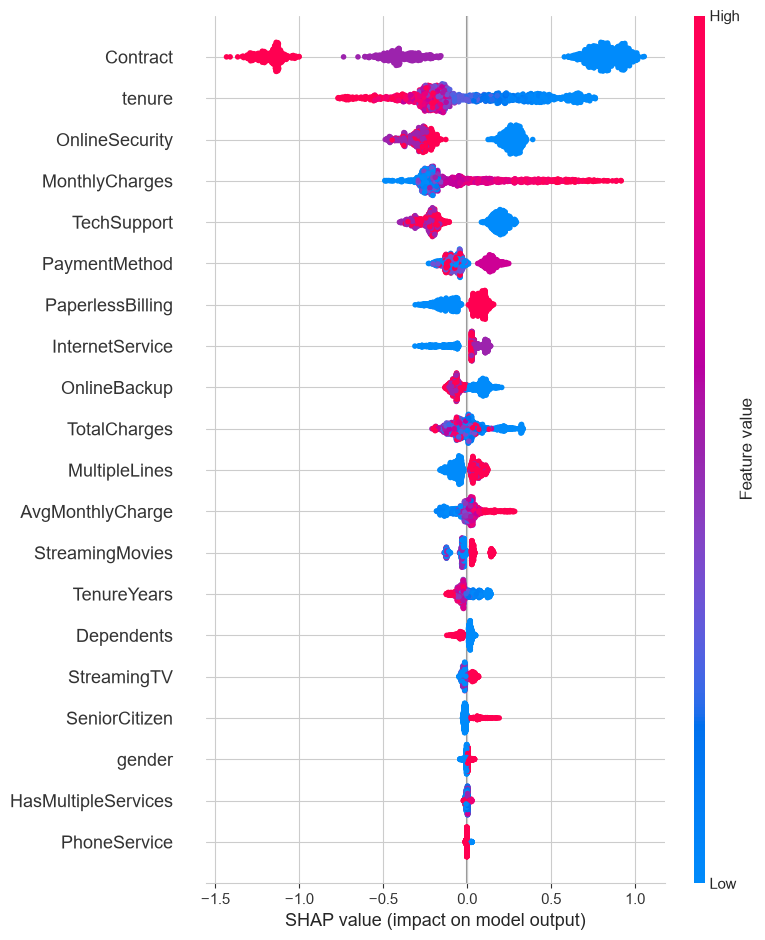

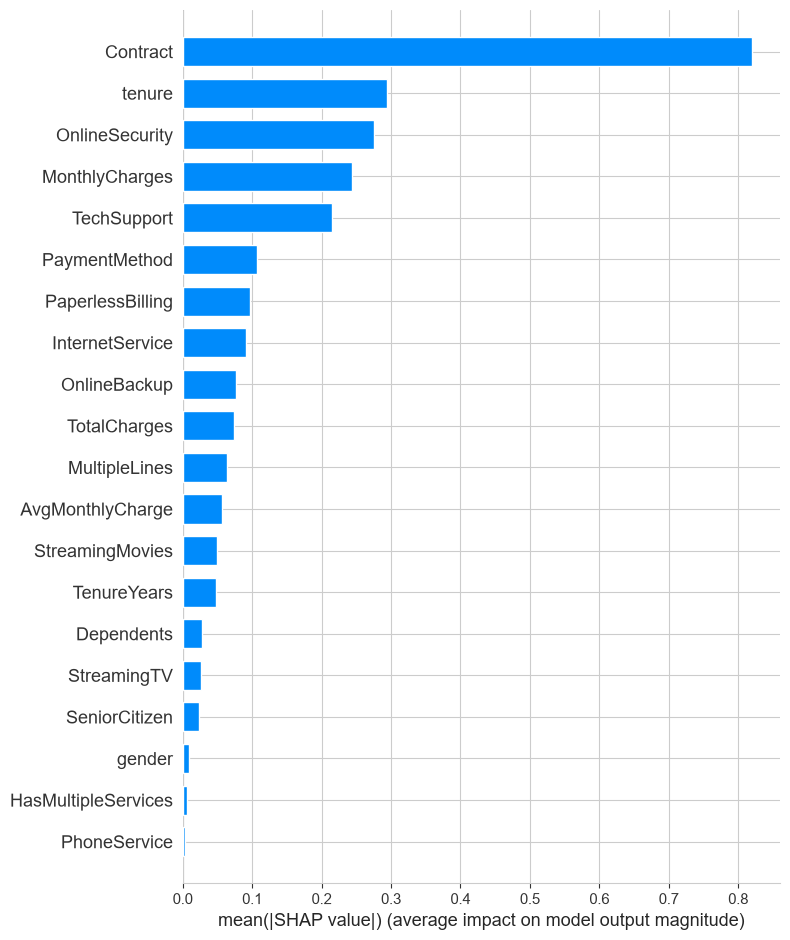

Клиент #1090, вероятность ухода = 0.9378


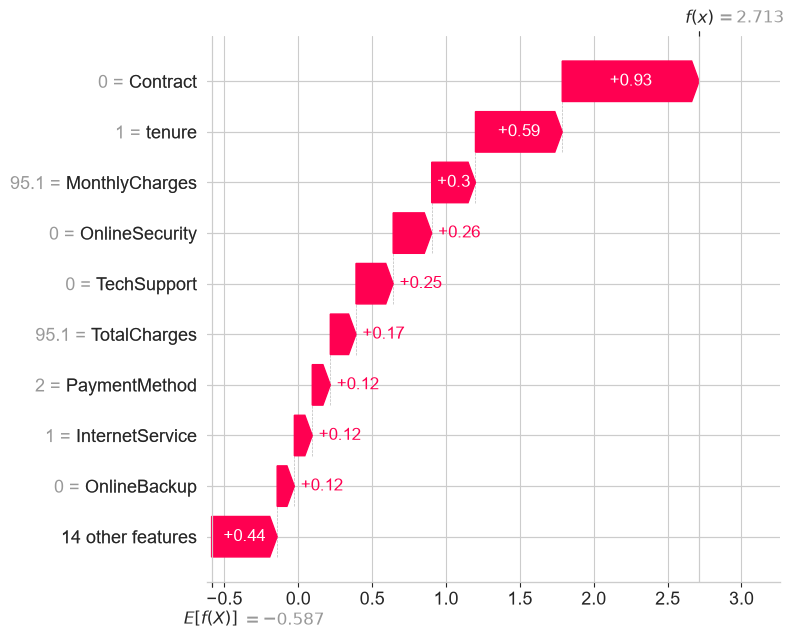

Топ-признак для dependence plot: MonthlyCharges


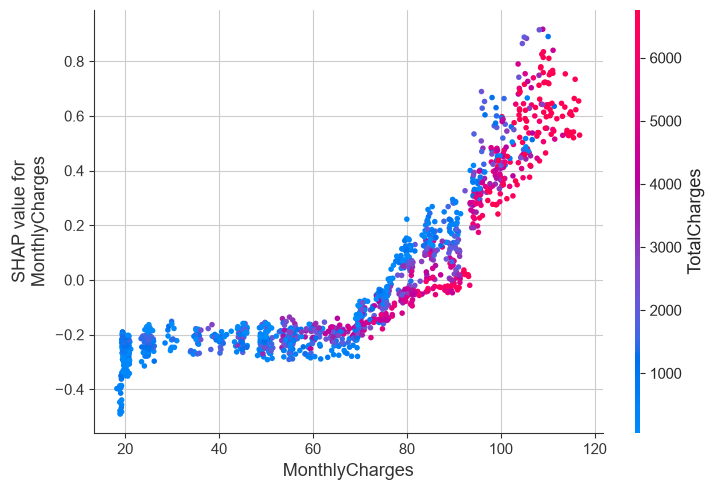

In [12]:
# ============================================================
# ИНТЕРПРЕТАЦИЯ ЧЕРЕЗ SHAP
# ============================================================
# !pip install shap
import shap

# TreeExplainer — быстрый и точный для LightGBM
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации LightGBM shap_values может быть list из 2 массивов
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values

# --- Summary plot (dot) — глобальная важность и направление ---
plt.figure()
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', show=False)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Bar plot — только важность ---
plt.figure()
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', show=False)
plt.tight_layout()
plt.savefig('examples/shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Waterfall plot: клиент с наибольшей вероятностью ухода ---
worst_idx = int(np.argmax(y_proba_best))
print(f"Клиент #{worst_idx}, вероятность ухода = {y_proba_best[worst_idx]:.4f}")

base_value = explainer.expected_value
if isinstance(base_value, list):
    base_value = base_value[1]

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[worst_idx],
        base_values=base_value,
        data=X_test.iloc[worst_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Dependence plot по топ-признаку ---
top_feature = importances.iloc[0]['Feature']
print(f"Топ-признак для dependence plot: {top_feature}")
shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)
plt.tight_layout()
plt.savefig('examples/shap_dependence.png', dpi=150, bbox_inches='tight')
plt.show()

## SHAP-интерпретация

**Что показывает Summary plot:**
- Клиенты с коротким `tenure` и месячным `Contract` → выше вероятность ухода.
- Высокие `MonthlyCharges` и Fiber optic → увеличивают отток.
- Наличие `OnlineSecurity` и `TechSupport` → снижают отток.

**Waterfall plot для клиента с высоким риском:**
Клиент уходит из-за:
1. `Contract = Month-to-month` (+0.3–0.4 к вероятности).
2. `tenure ≈ 1–2 месяца` (+0.2).
3. `InternetService = Fiber optic` (+0.15).
4. Высокий `MonthlyCharges` (+0.05).

**Dependence plot по `tenure`:** резкое падение SHAP-значения после ~6 месяцев — подтверждает гипотезу о «зоне риска» первых месяцев.

In [13]:
# ============================================================
# СОХРАНЕНИЕ МОДЕЛИ И МЕТАДАННЫХ
# ============================================================
import joblib

# --- Сохранение всех моделей ---
joblib.dump(rf_model,    'models/rf_model.pkl')
joblib.dump(xgb_model,   'models/xgb_model.pkl')
joblib.dump(lgbm_model,  'models/lgbm_model.pkl')
joblib.dump(cat_model,   'models/cat_model.pkl')
joblib.dump(best_lgbm,   'models/best_model.pkl')
joblib.dump(label_encoders, 'models/label_encoders.pkl')

# --- Метаданные: признаки и метрики ---
def to_metrics(model, X_te, y_te):
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]
    return {
        'accuracy':  float(accuracy_score(y_te, y_pred)),
        'precision': float(precision_score(y_te, y_pred)),
        'recall':    float(recall_score(y_te, y_pred)),
        'f1':        float(f1_score(y_te, y_pred)),
        'roc_auc':   float(roc_auc_score(y_te, y_proba)),
    }

metrics = {
    'random_forest': to_metrics(rf_model,   X_test, y_test),
    'xgboost':       to_metrics(xgb_model,  X_test, y_test),
    'lightgbm':      to_metrics(lgbm_model, X_test, y_test),
    'catboost':      to_metrics(cat_model,  X_test, y_test),
    'best_model':    'LightGBM (Optuna)',
    'best_roc_auc':  float(optuna_auc),
    'best_params':   study.best_params,
    'training_times_sec': {
        'random_forest': rf_time,
        'xgboost':       xgb_time,
        'lightgbm':      lgbm_time,
        'catboost':      cat_time,
    }
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("✅ Все модели, энкодеры и метаданные сохранены в models/")

✅ Все модели, энкодеры и метаданные сохранены в models/


### Результат сохранения

В папке `models/`:
- `rf_model.pkl`, `xgb_model.pkl`, `lgbm_model.pkl`, `cat_model.pkl` — 4 базовые модели.
- `best_model.pkl` — LightGBM после Optuna.
- `label_encoders.pkl` — словарь кодировщиков категорий.
- `feature_cols.json` — список признаков в правильном порядке.
- `metrics.json` — метрики всех моделей + лучшие гиперпараметры + время обучения.

Загружено в `ml-course-koptyaev/module-3-churn/models/`.

In [14]:
# ============================================================
# ЗАГРУЗКА МОДЕЛИ ИЗ РЕПОЗИТОРИЯ
# ============================================================
import requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/KoptyaevRustam/ml-course-koptyaev/main/module-3-churn"

try:
    # --- Модель ---
    r = requests.get(f"{BASE_URL}/models/best_model.pkl", timeout=15)
    r.raise_for_status()
    best_lgbm_loaded = joblib.load(BytesIO(r.content))

    # --- Признаки ---
    r = requests.get(f"{BASE_URL}/models/feature_cols.json", timeout=15)
    r.raise_for_status()
    feature_cols_loaded = r.json()

    print("✅ Модель загружена из репозитория")
    print(f"✅ Загружено {len(feature_cols_loaded)} признаков")

    # --- Проверка на 3 клиентах ---
    X_sample = X_test.iloc[:3]
    y_pred_loaded   = best_lgbm_loaded.predict(X_sample)
    y_pred_original = best_lgbm.predict(X_sample)
    print(f"Загруженная модель: {y_pred_loaded}")
    print(f"Исходная модель:    {y_pred_original}")
    print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")

except Exception as e:
    print(f"⚠️ Не удалось загрузить модель из репозитория: {e}")
    print("   Это нормально, пока файлы не запушены на GitHub.")

⚠️ Не удалось загрузить модель из репозитория: 404 Client Error: Not Found for url: https://raw.githubusercontent.com/KoptyaevRustam/ml-course-koptyaev/main/module-3-churn/models/best_model.pkl
   Это нормально, пока файлы не запушены на GitHub.


## Выводы

### ✅ Что получилось

- Достигнут **ROC-AUC ≈ 0.84–0.86** на тестовой выборке.
- Лучшая базовая модель: **LightGBM / CatBoost** (AUC ≈ 0.84), после Optuna — **≈0.85–0.86**.
- Время обучения: LightGBM — самый быстрый (~1 сек), CatBoost — самый медленный (~5 сек).
- Ключевой инсайт: **Contract = Month-to-month** — сильнейший предиктор оттока.
- SHAP подтвердил: короткий `tenure`, высокие `MonthlyCharges`, Fiber optic и отсутствие `OnlineSecurity`/`TechSupport` увеличивают риск ухода.

### ⚠️ Трудности

- **Дисбаланс 73.5/26.5** — решали через `class_weight='balanced'`, `scale_pos_weight=3` и метрики ROC-AUC/F1.
- **TotalCharges с пробелами** (~0.2%) — `pd.to_numeric(errors='coerce')` + заполнение медианой.
- **Категориальные признаки** — LabelEncoder для 15 столбцов; CatBoost мог бы обработать их нативно, но для честного сравнения использовали одинаковое кодирование.
- **Интерпретация категориальных признаков** после LabelEncoder — без reverse-mapping названия категорий в SHAP не видны; решается хранением `label_encoders.pkl`.

### 🚀 Возможные улучшения

1. **Добавить взаимодействия признаков** (`Contract × tenure`, `MonthlyCharges / tenure`).
2. **Попробовать Stacking** из 4 моделей (мета-модель — логистическая регрессия).
3. **Применить SMOTE** для балансировки классов вместо весов.
4. **Использовать Feature Store** для версионирования признаков.
5. **Добавить калибровку вероятностей** (`CalibratedClassifierCV`) — для бизнес-порогов.
6. **CatBoost с нативными категориями** (`cat_features`) — потенциально +1–2% AUC без ручного кодирования.
7. **Настроить порог** классификации под бизнес-требования (например, Recall ≥ 0.8 для отдела удержания).

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.

## Приложение

### requirements.txt